In [1]:
!pip install -q transformers sentencepiece

In [2]:
from transformers import AutoTokenizer
import pandas as pd

In [3]:
TOKENIZERS = {
    "BPE - GPT-2": "gpt2",
    "WordPiece - Multilingual BERT": "bert-base-multilingual-cased",
    "SentencePiece - XLM-R": "xlm-roberta-base"
}

In [4]:
TEXTS = {
    "English": "Artificial intelligence is changing the world.",
    "Telugu": "కృత్రిమ మేధస్సు ప్రపంచాన్ని మారుస్తోంది.",
    "Hindi": "कृत्रिम बुद्धिमत्ता दुनिया को बदल रही है।"
}

print("Input texts loaded successfully!")

Input texts loaded successfully!


In [5]:
def load_tokenizers():

    loaded = {}

    for display_name, model_name in TOKENIZERS.items():

        print(f"Loading {display_name}...")

        loaded[display_name] = AutoTokenizer.from_pretrained(
            model_name
        )

    return loaded


tokenizers = load_tokenizers()

print("\nAll tokenizers loaded successfully!")

Loading BPE - GPT-2...


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (7 outputs left out)

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]


All tokenizers loaded successfully!


In [6]:
results = []

def compare_tokenizers(loaded_tokenizers):

    for language, text in TEXTS.items():

        print("\n" + "=" * 80)
        print("LANGUAGE:", language)
        print("INPUT TEXT:", text)
        print("=" * 80)

        for tokenizer_name, tokenizer in loaded_tokenizers.items():

            encoded = tokenizer(
                text,
                add_special_tokens=True,
                truncation=False
            )

            token_ids = encoded["input_ids"]

            tokens = tokenizer.convert_ids_to_tokens(
                token_ids
            )

            token_count = len(token_ids)

            print("\n", tokenizer_name)
            print("Tokens:", tokens)
            print("Token IDs:", token_ids)
            print("Token Count:", token_count)

            results.append({
                "Language": language,
                "Tokenizer": tokenizer_name,
                "Input Text": text,
                "Tokens": str(tokens),
                "Token IDs": str(token_ids),
                "Token Count": token_count
            })


compare_tokenizers(tokenizers)


LANGUAGE: English
INPUT TEXT: Artificial intelligence is changing the world.

 BPE - GPT-2
Tokens: ['Art', 'ificial', 'Ġintelligence', 'Ġis', 'Ġchanging', 'Ġthe', 'Ġworld', '.']
Token IDs: [8001, 9542, 4430, 318, 5609, 262, 995, 13]
Token Count: 8

 WordPiece - Multilingual BERT
Tokens: ['[CLS]', 'Arti', '##ficial', 'intelligence', 'is', 'changing', 'the', 'world', '.', '[SEP]']
Token IDs: [101, 90841, 69229, 30151, 10124, 43068, 10105, 11356, 119, 102]
Token Count: 10

 SentencePiece - XLM-R
Tokens: ['<s>', '▁Artificial', '▁', 'intelligence', '▁is', '▁changing', '▁the', '▁world', '.', '</s>']
Token IDs: [0, 231996, 6, 130687, 83, 151134, 70, 8999, 5, 2]
Token Count: 10

LANGUAGE: Telugu
INPUT TEXT: కృత్రిమ మేధస్సు ప్రపంచాన్ని మారుస్తోంది.

 BPE - GPT-2
Tokens: ['à', '°', 'ķ', 'à', '±', 'ĥ', 'à', '°', '¤', 'à', '±', 'į', 'à', '°', '°', 'à', '°', '¿', 'à', '°', '®', 'Ġ', 'à', '°', '®', 'à', '±', 'ĩ', 'à', '°', '§', 'à', '°', '¸', 'à', '±', 'į', 'à', '°', '¸', 'à', '±', 'ģ', 'Ġ', 'à', '

In [7]:
df = pd.DataFrame(results)

display(df)

,Language,Tokenizer,Input Text,Tokens,Token IDs,Token Count
0,English,BPE - GPT-2,Artificial intelligence is changing the world.,"['Art', 'ificial', 'Ġintelligence', 'Ġis', 'Ġc...","[8001, 9542, 4430, 318, 5609, 262, 995, 13]",8
1,English,WordPiece - Multilingual BERT,Artificial intelligence is changing the world.,"['[CLS]', 'Arti', '##ficial', 'intelligence', ...","[101, 90841, 69229, 30151, 10124, 43068, 10105...",10
2,English,SentencePiece - XLM-R,Artificial intelligence is changing the world.,"['<s>', '▁Artificial', '▁', 'intelligence', '▁...","[0, 231996, 6, 130687, 83, 151134, 70, 8999, 5...",10
3,Telugu,BPE - GPT-2,కృత్రిమ మేధస్సు ప్రపంచాన్ని మారుస్తోంది.,"['à', '°', 'ķ', 'à', '±', 'ĥ', 'à', '°', '¤', ...","[156, 108, 243, 156, 109, 225, 156, 108, 97, 1...",112
4,Telugu,WordPiece - Multilingual BERT,కృత్రిమ మేధస్సు ప్రపంచాన్ని మారుస్తోంది.,"['[CLS]', 'క', '##ృ', '##త్రి', '##మ', 'మ', '#...","[101, 1201, 111339, 88046, 24696, 1224, 17729,...",18
5,Telugu,SentencePiece - XLM-R,కృత్రిమ మేధస్సు ప్రపంచాన్ని మారుస్తోంది.,"['<s>', '▁', 'కృత', '్రి', 'మ', '▁మే', 'ధ', 'స...","[0, 6, 151424, 91445, 3071, 22290, 11600, 1294...",14
6,Hindi,BPE - GPT-2,कृत्रिम बुद्धिमत्ता दुनिया को बदल रही है।,"['à¤', 'ķ', 'à¥', 'ĥ', 'à¤', '¤', 'à¥', 'į', '...","[11976, 243, 24231, 225, 11976, 97, 24231, 235...",68
7,Hindi,WordPiece - Multilingual BERT,कृत्रिम बुद्धिमत्ता दुनिया को बदल रही है।,"['[CLS]', 'क', '##ृत', '##्र', '##िम', 'ब', '#...","[101, 865, 37500, 18321, 50419, 887, 48010, 50...",17
8,Hindi,SentencePiece - XLM-R,कृत्रिम बुद्धिमत्ता दुनिया को बदल रही है।,"['<s>', '▁कृत', '्रि', 'म', '▁बुद्धि', 'म', 'त...","[0, 74707, 97885, 1920, 105202, 1920, 54297, 2...",14


In [8]:
df = pd.DataFrame(results)

display(df)

,Language,Tokenizer,Input Text,Tokens,Token IDs,Token Count
0,English,BPE - GPT-2,Artificial intelligence is changing the world.,"['Art', 'ificial', 'Ġintelligence', 'Ġis', 'Ġc...","[8001, 9542, 4430, 318, 5609, 262, 995, 13]",8
1,English,WordPiece - Multilingual BERT,Artificial intelligence is changing the world.,"['[CLS]', 'Arti', '##ficial', 'intelligence', ...","[101, 90841, 69229, 30151, 10124, 43068, 10105...",10
2,English,SentencePiece - XLM-R,Artificial intelligence is changing the world.,"['<s>', '▁Artificial', '▁', 'intelligence', '▁...","[0, 231996, 6, 130687, 83, 151134, 70, 8999, 5...",10
3,Telugu,BPE - GPT-2,కృత్రిమ మేధస్సు ప్రపంచాన్ని మారుస్తోంది.,"['à', '°', 'ķ', 'à', '±', 'ĥ', 'à', '°', '¤', ...","[156, 108, 243, 156, 109, 225, 156, 108, 97, 1...",112
4,Telugu,WordPiece - Multilingual BERT,కృత్రిమ మేధస్సు ప్రపంచాన్ని మారుస్తోంది.,"['[CLS]', 'క', '##ృ', '##త్రి', '##మ', 'మ', '#...","[101, 1201, 111339, 88046, 24696, 1224, 17729,...",18
5,Telugu,SentencePiece - XLM-R,కృత్రిమ మేధస్సు ప్రపంచాన్ని మారుస్తోంది.,"['<s>', '▁', 'కృత', '్రి', 'మ', '▁మే', 'ధ', 'స...","[0, 6, 151424, 91445, 3071, 22290, 11600, 1294...",14
6,Hindi,BPE - GPT-2,कृत्रिम बुद्धिमत्ता दुनिया को बदल रही है।,"['à¤', 'ķ', 'à¥', 'ĥ', 'à¤', '¤', 'à¥', 'į', '...","[11976, 243, 24231, 225, 11976, 97, 24231, 235...",68
7,Hindi,WordPiece - Multilingual BERT,कृत्रिम बुद्धिमत्ता दुनिया को बदल रही है।,"['[CLS]', 'क', '##ृत', '##्र', '##िम', 'ब', '#...","[101, 865, 37500, 18321, 50419, 887, 48010, 50...",17
8,Hindi,SentencePiece - XLM-R,कृत्रिम बुद्धिमत्ता दुनिया को बदल रही है।,"['<s>', '▁कृत', '्रि', 'म', '▁बुद्धि', 'म', 'त...","[0, 74707, 97885, 1920, 105202, 1920, 54297, 2...",14


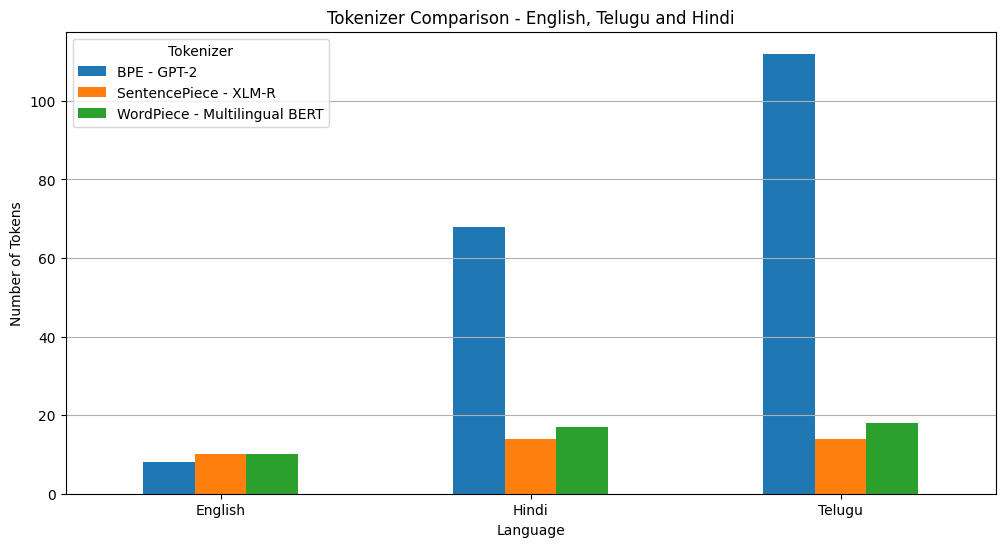

In [9]:
import matplotlib.pyplot as plt

pivot_df = df.pivot(
    index="Language",
    columns="Tokenizer",
    values="Token Count"
)

pivot_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Tokenizer Comparison - English, Telugu and Hindi")
plt.xlabel("Language")
plt.ylabel("Number of Tokens")
plt.xticks(rotation=0)
plt.legend(title="Tokenizer")
plt.grid(axis="y")

plt.show()